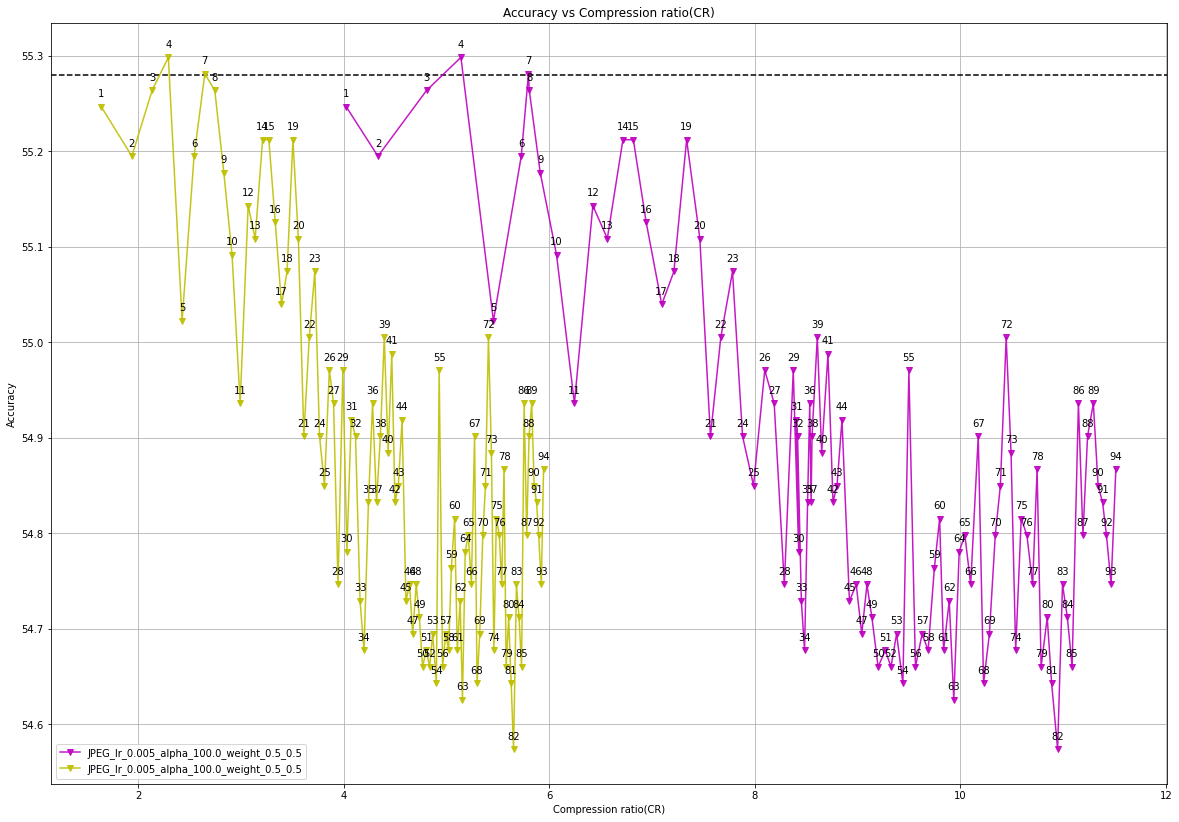

In [2]:
import matplotlib.pyplot as plt
import os
import numpy as np
# from sklearn.preprocessing import PolynomialFeatures
# from sklearn.linear_model import LinearRegression

def read_file(file_path):
    data = []
    with open(file_path, 'r') as file:
        next(file)  # ignore the first line
        for line in file:
            parts = line.split()
            if len(parts) == 17:
                row = list(map(float, parts))
                data.append(row)
    return data


def get_greedy(x_values, y_values):
    # Sort data by y_values while keeping x_values in corresponding order
    sorted_pairs = sorted(zip(y_values, x_values, range(len(y_values))), key=lambda x: x[0], reverse=True)
    sorted_y_values, sorted_x_values, sorted_index = zip(*sorted_pairs)  # Unzip pairs into separate lists

    best_y = sorted_y_values[0]
    best_x = sorted_x_values[0]
    print("Best accuracy: {y:.8f} at epoch: {index:.0f} with CR: {x:.8f}".format(y=best_y, index=sorted_index[0]+1, x=best_x))
    
    new_y = []
    new_x = []
    new_index = []
    for index, y_value in enumerate(sorted_y_values):
        if sorted_x_values[index] >= best_x and y_value <= best_y:
            best_x = sorted_x_values[index]
            best_y = y_value
            new_y.append(y_value)
            new_x.append(sorted_x_values[index])
            new_index.append(sorted_index[index])
    
    return new_x, new_y, new_index


def plot_data_bpp(file_path, marker, label, color, greedy=True):
    data = read_file(file_path)
    y_values = [row[2] for row in data] # test acc
    # x_values = [269.63494 / (row[7] + row[8] + row[9] + row[10]) for row in data] # CR
    x_values = [(24 / row[6]) for row in data] # bpp
    
    if len(x_values) > 100:
        y_values = y_values[:100]
        x_values = x_values[:100]
    # x_values = [row[4] for row in data] # test loss

    if greedy:
        new_x_values, new_y_values, new_index = get_greedy(x_values, y_values)
        plt.plot(x_values, y_values, marker=marker, color=color, alpha=0.2, linestyle="")
        plt.plot(new_x_values, new_y_values, marker=marker, label=label, color=color, alpha=1)
        for i, (x, y) in enumerate(zip(new_x_values, new_y_values)):
            plt.annotate("ep:" + str(new_index[i]+1), (x, y), textcoords="offset points", xytext=(0,10), ha='center')
        return new_index[0]+1
    else:
        # plt.plot(x_values, y_values, marker=marker, label=label, color=color, alpha=0.9, linestyle="")
        plt.plot(x_values, y_values, marker=marker, label=label, color=color, alpha=0.9)
        for i, (x, y) in enumerate(zip(x_values, y_values)):
            plt.annotate(str(i+1), (x, y), textcoords="offset points", xytext=(0,10), ha='center')
        return -1


def plot_data_entropy(file_path, marker, label, color, greedy=True):
    data = read_file(file_path)
    y_values = [row[2] for row in data] # test acc
    x_values = [269.63494 / (row[7] + row[8] + row[9] + row[10]) for row in data] # CR
    # x_values = [24 / (row[6]) for row in data] # bpp
    
    if len(x_values) > 100:
        y_values = y_values[:100]
        x_values = x_values[:100]
    # x_values = [row[4] for row in data] # test loss

    if greedy:
        new_x_values, new_y_values, new_index = get_greedy(x_values, y_values)
        plt.plot(x_values, y_values, marker=marker, color=color, alpha=0.2, linestyle="")
        plt.plot(new_x_values, new_y_values, marker=marker, label=label, color=color, alpha=1)
        for i, (x, y) in enumerate(zip(new_x_values, new_y_values)):
            plt.annotate("ep:" + str(new_index[i]+1), (x, y), textcoords="offset points", xytext=(0,10), ha='center')
        return new_index[0]+1
    else:
        # plt.plot(x_values, y_values, marker=marker, label=label, color=color, alpha=0.9, linestyle="")
        plt.plot(x_values, y_values, marker=marker, label=label, color=color, alpha=0.9)
        for i, (x, y) in enumerate(zip(x_values, y_values)):
            plt.annotate(str(i+1), (x, y), textcoords="offset points", xytext=(0,10), ha='center')
        return -1


def plot_data_average(base_path):
    total_y_sums = []
    total_x_sums = []
    
    file_count = 0
    for trial_folder in os.listdir(base_path):
        folder_path = os.path.join(base_path, trial_folder)
        if os.path.isdir(folder_path):
            log_file_path = os.path.join(folder_path, 'logs.txt')
            print(log_file_path)
            if os.path.exists(log_file_path):
                data = read_file(log_file_path)
                y_values = [row[2] for row in data] # test acc
                x_values = [269.63494 / (row[7] + row[8] + row[9] + row[10]) for row in data] # CR
                if not total_y_sums:
                    total_y_sums = y_values
                    total_x_sums = x_values
                else:
                    total_y_sums = [sum(x) for x in zip(total_y_sums, y_values)]
                    total_x_sums = [sum(x) for x in zip(total_x_sums, x_values)]
                file_count += 1
    if file_count > 0:
        average_y = [y / file_count for y in total_y_sums]
        average_x = [x / file_count for x in total_x_sums]
    
    print(len(average_x))
    plt.plot(average_x, average_y, marker="^", label='JPEG_lr_0.01_alpha_100.0')


plt.figure(figsize=(20, 14))
plt.axhline(y=55.28, color='black', linestyle='--') # baseline

color_list = ['r','g','b','m','y','c','#7f7f7f','k','#e377c2']
marker_list = ['o','^','.','v','>','v','|','_',',','x']
base_path = './save/CUB200/resnet18'

file_name_1 = "JPEG_lr_{}_alpha_{}_weight_{}_{}".format(0.005, 100.0, 0.01, 0.01)
file_name_2 = "JPEG_lr_{}_alpha_{}_weight_{}_{}".format(0.005, 100.0, 0.05, 0.05)
file_name_3 = "JPEG_lr_{}_alpha_{}_weight_{}_{}".format(0.005, 100.0, 0.075, 0.075)
file_name_4 = "JPEG_lr_{}_alpha_{}_weight_{}_{}".format(0.005, 100.0, 0.5, 0.5)
file_name_5 = "JPEG_lr_{}_alpha_{}_weight_{}_{}".format(0.005, 100.0, 0.125, 0.125)
file_name_6 = "JPEG_lr_{}_alpha_{}_weight_{}_{}".format(0.005, 100.0, 0.15, 0.15)
file_name_7 = "JPEG_lr_{}_alpha_{}_weight_{}_{}".format(0.005, 100.0, 0.175, 0.175)
file_name_8 = "JPEG_lr_{}_alpha_{}_weight_{}_{}".format(0.005, 100.0, 0.2, 0.2)
file_name_9 = "JPEG_lr_{}_alpha_{}_weight_{}_{}".format(0.005, 100.0, 0.225, 0.225)

# best_epoch_1 = plot_data_bpp(os.path.join(os.path.join(base_path, file_name_1), "trial_1/logs.txt"), marker_list[0], file_name_1, color=color_list[0], greedy=True)
# best_epoch_2 = plot_data_bpp(os.path.join(os.path.join(base_path, file_name_2), "trial_1/logs.txt"), marker_list[1], file_name_2, color=color_list[1], greedy=True)
# best_epoch_3 = plot_data_bpp(os.path.join(os.path.join(base_path, file_name_3), "trial_1/logs.txt"), marker_list[2], file_name_3, color=color_list[2], greedy=True)
best_epoch_4 = plot_data_bpp(os.path.join(os.path.join(base_path, file_name_4), "trial_1/logs.txt"), marker_list[3], file_name_4, color=color_list[3], greedy=False)
best_epoch_4 = plot_data_entropy(os.path.join(os.path.join(base_path, file_name_4), "trial_1/logs.txt"), marker_list[3], file_name_4, color=color_list[4], greedy=False)
# best_epoch_5 = plot_data_bpp(os.path.join(os.path.join(base_path, file_name_5), "trial_1/logs.txt"), marker_list[4], file_name_5, color=color_list[4], greedy=True)
# best_epoch_6 = plot_data_bpp(os.path.join(os.path.join(base_path, file_name_6), "trial_1/logs.txt"), marker_list[5], file_name_6, color=color_list[5], greedy=True)
# best_epoch_7 = plot_data_bpp(os.path.join(os.path.join(base_path, file_name_7), "trial_1/logs.txt"), marker_list[6], file_name_7, color=color_list[6], greedy=True)
# best_epoch_8 = plot_data_bpp(os.path.join(os.path.join(base_path, file_name_8), "trial_1/logs.txt"), marker_list[7], file_name_8, color=color_list[7], greedy=True)
# best_epoch_9 = plot_data_bpp(os.path.join(os.path.join(base_path, file_name_9), "trial_1/logs.txt"), marker_list[8], file_name_9, color=color_list[8], greedy=True)
# plot_data_average('./save/CUB200/resnet18/JPEG_lr_0.015_alpha_100.0_weight_0.1_0.1')

plt.xlabel('Compression ratio(CR)')
plt.ylabel('Accuracy')
plt.title('Accuracy vs Compression ratio(CR)')
plt.legend(loc="lower left")
plt.grid(True)
plt.show()

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


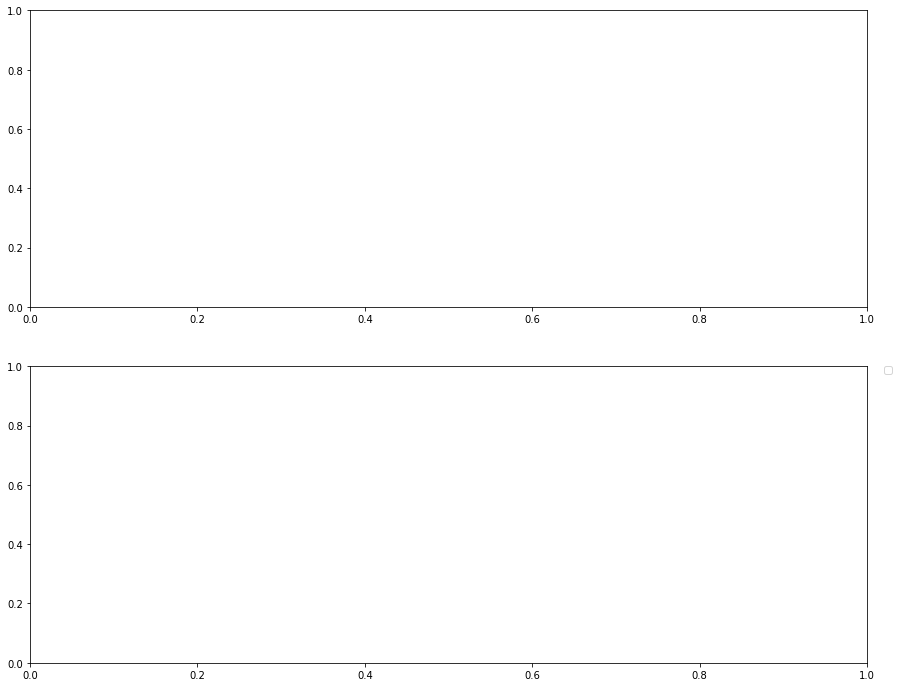

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import os


def zigzag(matrix):
    zigzag = np.array([[0, 1, 5, 6, 14, 15, 27, 28],
                        [2, 4, 7, 13, 16, 26, 29, 42],
                        [3, 8, 12, 17, 25, 30, 41, 43],
                        [9, 11, 18, 24, 31, 40, 44, 53],
                        [10, 19, 23, 32, 39, 45, 52, 54],
                        [20, 22, 33, 38, 46, 51, 55, 60],
                        [21, 34, 37, 47, 50, 56, 59, 61],
                        [35, 36, 48, 49, 57, 58, 62, 63]])
    matrix_size = np.shape(matrix)
    vector_size = np.shape(zigzag)
    if matrix_size != vector_size:
        raise ValueError("The matrix size does not match the vector size.")
    vector = np.zeros(matrix_size[0] * matrix_size[1])
    for i in range(matrix_size[0]):
        for j in range(matrix_size[1]):
            index = zigzag[i, j]
            vector[index] = matrix[i, j]
    return vector


def plot_q_table(filepaths, marker, color, label, epoch_choose=-1):
    with open(os.path.join(filepaths, "lum_q_table.txt"), "r") as lum_file:
        lum_lines = lum_file.read()
    lum_q_tables = lum_lines.split("\n\n")[:-1]
    
    with open(os.path.join(filepaths, "chrom_q_table.txt"), "r") as chrom_file:
        chrom_lines = chrom_file.read()
    chrom_q_tables = chrom_lines.split("\n\n")[:-1]
    
    for epoch, q_table in enumerate(lum_q_tables): 
        # if epoch % 10 != 0 and epoch != 99:
        #     continue
        if epoch != epoch_choose:
            continue
        matrix = np.array([list(map(float, row.split(","))) for row in q_table.split("\n")])
        matrix = zigzag(matrix).flatten()
        # ax1.plot(matrix, marker=marker, color=color, label=label, alpha=0.5)
        ax1.plot(matrix, marker=marker, label=label+" epoch {}".format(epoch), alpha=0.5)
        ax1.set_xlabel('Frequency Index')
        ax1.set_ylabel('Lum Q steps')
        ax1.set_title('Lum Q steps vs Frequency Index')
        ax1.grid(True)
        
    for epoch, q_table in enumerate(chrom_q_tables):
        # if epoch % 10 != 0 and epoch != 99:
        #     continue
        if epoch != epoch_choose:
            continue
        matrix = np.array([list(map(float, row.split(","))) for row in q_table.split("\n")])
        matrix = zigzag(matrix).flatten()
        # ax2.plot(matrix, marker=marker, color=color, label=label, alpha=0.5)
        ax2.plot(matrix, marker=marker, label=label+" epoch {}".format(epoch), alpha=0.5)
        ax2.set_xlabel('Frequency Index')
        ax2.set_ylabel('Chrom Q steps')
        ax2.set_title('Chrom Q steps vs Frequency Index')
        ax2.grid(True)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 12))

base_path = './save/CUB200/resnet18'
logs_path_1 = os.path.join(os.path.join(base_path, file_name_1), "trial_1/Q_tables")
logs_path_2 = os.path.join(os.path.join(base_path, file_name_2), "trial_1/Q_tables")
logs_path_3 = os.path.join(os.path.join(base_path, file_name_3), "trial_1/Q_tables")
logs_path_4 = os.path.join(os.path.join(base_path, file_name_4), "trial_1/Q_tables")
logs_path_5 = os.path.join(os.path.join(base_path, file_name_5), "trial_1/Q_tables")
logs_path_6 = os.path.join(os.path.join(base_path, file_name_6), "trial_1/Q_tables")

# plot_q_table(logs_path_1, marker_list[0], color_list[0], file_name_1, best_epoch_1)
# plot_q_table(logs_path_2, marker_list[1], color_list[1], file_name_2, best_epoch_2)
# plot_q_table(logs_path_3, marker_list[2], color_list[2], file_name_3, best_epoch_3)
plot_q_table(logs_path_4, marker_list[3], color_list[3], file_name_4, best_epoch_4)
# plot_q_table(logs_path_5, marker_list[4], color_list[4], file_name_5, best_epoch_5)
# plot_q_table(logs_path_6, marker_list[5], color_list[5], file_name_6, best_epoch_6)

plt.subplots_adjust(hspace=0.2)
plt.legend(bbox_to_anchor=(1.02, 1), loc=2, borderaxespad=0)
plt.show()

In [ ]:
import torch

loaded_tensor = torch.load('./save/CUB200/resnet18/JPEG_lr_0.01_alpha_100.0_alpha_lr_None_weight_0.0_0.0_alpha_untrainable/trial_1/Q_tables/q_table_epoch_61.pt')
print(loaded_tensor[0])
print(loaded_tensor[1])

tensor([[1.4206, 2.0837, 1.2303, 1.1523, 1.0283, 1.0106, 1.0295, 1.0229],
        [1.8261, 1.1545, 1.3068, 1.0078, 1.1106, 1.0308, 1.0108, 1.0023],
        [2.1039, 1.0458, 1.0166, 1.3009, 1.0156, 1.0572, 1.0172, 1.0063],
        [1.6128, 1.0434, 1.0671, 1.0149, 1.0040, 1.0132, 1.0081, 1.0042],
        [1.0364, 1.2643, 1.0014, 1.0146, 1.0262, 1.0043, 1.0035, 1.0013],
        [1.0294, 1.0068, 1.0086, 1.0068, 1.0049, 1.0018, 1.0004, 1.0007],
        [1.0105, 1.0074, 1.0067, 1.0059, 1.0026, 1.0013, 1.0010, 1.0003],
        [1.0167, 1.0067, 1.0166, 1.0062, 1.0011, 1.0011, 1.0012, 1.0007]])
tensor([[16.1663,  1.6603,  1.0047,  1.0753,  1.0177,  1.0052,  1.0025,  1.0037],
        [ 1.5264,  1.3140,  1.0139,  1.0275,  1.0032,  1.0032,  1.0014,  1.0002],
        [ 1.4535,  1.1264,  1.0400,  1.0038,  1.0031,  1.0014,  1.0001,  1.0011],
        [ 1.0090,  1.0323,  1.0049,  1.0061,  1.0047,  1.0007,  1.0017,  1.0002],
        [ 1.0096,  1.0026,  1.0083,  1.0017,  1.0005,  1.0003,  1.0002,  1.0000

In [ ]:
mismatch_count = 0
total = 0

with open('./save/CUB200/resnet18/output_target.txt', 'r') as file:
    for line in file:
        total += 1
        predicted, true = map(int, line.strip().split())
        
        if predicted != true:
            mismatch_count += 1

acc = 1- mismatch_count / total
print(f"acc: {acc}")


acc: 0.5519502934069727
